# 07 — Interactive TimeGuessr: Play Against the AI

Play any live **TimeGuessr** game alongside our models!

**How to use this notebook:**
1. **Pick a model** in Section 1 (`streetclip_finetune`, `streetclip_linear_probe`, `streetclip_linear_probe_tuned`, `siglip2_linear_probe`, or `siglip2_finetune` — or plug in any custom `BaseTimeguessrPredictor`).
2. **Paste a TimeGuessr game URL** in Section 2 (e.g., `https://timeguessr.com/play?mode=daily` or an archive/custom game link). This fetches all 5 photos, ground-truth answers, and the all-player score distribution — **without spoiling any answers**.
3. **Play Round 1 on TimeGuessr**, then run the **Round 1** cell to see what the AI guessed, its map pin vs. ground truth, and its exact score. Repeat one cell at a time for Rounds 2–5!
4. **Enter your final score** in Section 4 to see how you stacked up against the AI and the all-player score distribution.

## 1. Setup & Model Selection

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.collections import PolyCollection
import numpy as np
import pandas as pd
import requests
import torch
from IPython.display import HTML, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

from timeguessr_ai import (
    fetch_timeguessr_game,
    format_device_info,
    get_default_device,
    load_dataset_and_tiles,
    load_predictor,
    score_round,
)

DEVICE = str(get_default_device())
print(f"Project root: {PROJECT_ROOT}")
print(f"Device:       {format_device_info(DEVICE)}")

W1124 19:35:50.898000 26756 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


Project root: d:\VSCodeProjects\CS441
Device:       cuda (NVIDIA GeForce RTX 4070 SUPER)


In [20]:
# --- INPUT: Choose model ---
# Available presets:
#   - "streetclip_finetune"           : Fine-tuned StreetCLIP ViT-L/14
#   - "streetclip_linear_probe"       : Frozen StreetCLIP + Dual MLP heads
#   - "streetclip_linear_probe_tuned" : Tuned Frozen StreetCLIP + Dual MLP heads
#   - "siglip2_linear_probe"          : Frozen SigLIP 2 + Dual MLP heads
#   - "linear_probe" / "finetuned"    : Custom checkpoint via MODEL_KWARGS["checkpoint_path"]
MODEL_TYPE = "streetclip_linear_probe_tuned"
MODEL_KWARGS = {}

In [21]:
predictor = load_predictor(MODEL_TYPE, project_root=PROJECT_ROOT, device=DEVICE, **MODEL_KWARGS)
print(f"Loaded predictor: {predictor.name}")

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] CLIPVisionModel LOAD REPORT from: geolocal/StreetCLIP
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.self_attn.v_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm2.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
logit_scale                                        

Loaded predictor: Linear Probe (StreetCLIP (ViT-L/14@336))


## 2. Load a TimeGuessr Game (Spoiler-Free)

Paste any TimeGuessr game URL below (for example `https://timeguessr.com/play?mode=daily`, an archive URL, or a custom game link).
Ground-truth years, coordinates, and descriptions stay hidden until you run each round cell.

In [22]:
# --- INPUT: Paste TimeGuessr game link ---
GAME_URL = "https://timeguessr.com/play?mode=daily"

In [23]:
game = fetch_timeguessr_game(GAME_URL, download_images=True, fetch_distribution=True)

# Programmatically download & cache Natural Earth world country outlines (public domain, no API key)
WORLD_MAP_URL = "https://raw.githubusercontent.com/nvkelso/natural-earth-vector/master/geojson/ne_110m_admin_0_countries.geojson"
WORLD_MAP_PATH = PROJECT_ROOT / "data" / "maps" / "ne_110m_admin_0_countries.geojson"
if not WORLD_MAP_PATH.exists():
    WORLD_MAP_PATH.parent.mkdir(parents=True, exist_ok=True)
    print(f"Downloading offline world map to {WORLD_MAP_PATH}...")
    _resp = requests.get(WORLD_MAP_URL, timeout=20)
    _resp.raise_for_status()
    WORLD_MAP_PATH.write_bytes(_resp.content)

_world_gj = json.loads(WORLD_MAP_PATH.read_text(encoding="utf-8"))
_WORLD_POLYS = []
for _feat in _world_gj["features"]:
    _geom = _feat.get("geometry") or {}
    _gtype = _geom.get("type")
    _coords = _geom.get("coordinates") or []
    if _gtype == "Polygon" and _coords:
        _WORLD_POLYS.append(np.asarray(_coords[0], dtype=np.float64))
    elif _gtype == "MultiPolygon":
        for _poly in _coords:
            if _poly:
                _WORLD_POLYS.append(np.asarray(_poly[0], dtype=np.float64))

# State dictionary tracking each played round
round_results = {}

title_bits = [f"Mode: {game.mode}"]
if game.daily_no:
    title_bits.append(f"Daily #{game.daily_no}")
if game.game_id:
    title_bits.append(f"Game ID: {game.game_id}")
print("Loaded TimeGuessr game | " + " | ".join(title_bits))
print(f"Rounds downloaded: {len(game.rounds)} / 5 (answers hidden until you run each round)")
if game.distribution is not None:
    print(f"All-player distribution loaded ({len(game.distribution.histogram)} bins, mean={game.distribution.avg_score:,.0f})")
else:
    print("All-player distribution not yet available for this game (will still score all 5 rounds).")

Loaded TimeGuessr game | Mode: daily | Daily #1273
Rounds downloaded: 5 / 5 (answers hidden until you run each round)
All-player distribution loaded (50 bins, mean=37,176)


In [24]:
def _great_circle_arc(lat1, lon1, lat2, lon2, n_pts=80):
    """Return (lats, lons) along the shortest great-circle path between two points."""
    p1 = np.radians([lat1, lon1])
    p2 = np.radians([lat2, lon2])
    v1 = np.array([np.cos(p1[0]) * np.cos(p1[1]), np.cos(p1[0]) * np.sin(p1[1]), np.sin(p1[0])])
    v2 = np.array([np.cos(p2[0]) * np.cos(p2[1]), np.cos(p2[0]) * np.sin(p2[1]), np.sin(p2[0])])
    omega = np.arccos(np.clip(np.dot(v1, v2), -1.0, 1.0))
    if omega < 1e-6:
        return np.array([lat1, lat2]), np.array([lon1, lon2])
    t = np.linspace(0.0, 1.0, n_pts)
    s1 = np.sin((1.0 - t) * omega) / np.sin(omega)
    s2 = np.sin(t * omega) / np.sin(omega)
    pts = s1[:, None] * v1[None, :] + s2[:, None] * v2[None, :]
    lats = np.degrees(np.arcsin(np.clip(pts[:, 2], -1.0, 1.0)))
    lons = np.degrees(np.arctan2(pts[:, 1], pts[:, 0]))
    jumps = np.where(np.abs(np.diff(lons)) > 180.0)[0]
    if len(jumps):
        lats = np.insert(lats, jumps + 1, np.nan)
        lons = np.insert(lons, jumps + 1, np.nan)
    return lats, lons


def play_round(round_num: int, your_score: int | None = None):
    """Run AI inference on `round_num` (1..5), display photo + map + scores, and update running total."""
    rd = game.get_round(round_num)
    if rd.image is None:
        raise RuntimeError(f"Round {round_num} image was not downloaded.")

    pred = predictor.predict(rd.image)
    sc = score_round(
        true_lat=rd.true_lat,
        true_lon=rd.true_lon,
        true_year=rd.true_year,
        pred_lat=pred.pred_lat,
        pred_lon=pred.pred_lon,
        pred_year=pred.pred_year,
    )
    r_stats = game.distribution.round_stats(round_num) if game.distribution is not None else None

    entry = {
        "round": round_num,
        "true_year": rd.true_year,
        "pred_year": sc["pred_year_int"],
        "pred_year_raw": pred.pred_year_raw,
        "years_off": sc["years_off"],
        "true_lat": rd.true_lat,
        "true_lon": rd.true_lon,
        "pred_lat": pred.pred_lat,
        "pred_lon": pred.pred_lon,
        "true_country": rd.country,
        "pred_location": pred.location_label,
        "dist_km": sc["dist_km"],
        "year_score": sc["year_score"],
        "loc_score": sc["loc_score"],
        "total_score": sc["total_score"],
        "player_avg_score": r_stats.avg_score if r_stats else None,
        "your_score": your_score,
        "reasoning": pred.reasoning,
        "description": rd.description,
    }
    round_results[round_num] = entry

    running_ai = sum(r["total_score"] for r in round_results.values())
    max_so_far = len(round_results) * 10000

    # --- Plot: Round Photo + World/Regional Guess Map ---
    fig, (ax_img, ax_map) = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.05, 1.25]})
    fig.patch.set_facecolor("#fafafa")

    ax_img.imshow(rd.image)
    ax_img.set_title(f"Round {round_num} Photo  |  True Year: {rd.true_year} ({rd.country})", fontsize=12, fontweight="bold")
    ax_img.axis("off")

    ax_map.set_facecolor("#d8eaf6")
    ax_map.add_collection(
        PolyCollection(_WORLD_POLYS, facecolor="#eef1f4", edgecolor="#94a3b8", linewidth=0.55, zorder=1)
    )
    arc_lats, arc_lons = _great_circle_arc(pred.pred_lat, pred.pred_lon, rd.true_lat, rd.true_lon)
    ax_map.plot(arc_lons, arc_lats, linestyle="--", color="#1e293b", linewidth=1.8, alpha=0.85, zorder=2)
    ax_map.scatter([pred.pred_lon], [pred.pred_lat], s=120, c="#2563eb", edgecolors="white", linewidth=1.5, label=f"AI Guess ({pred.pred_year})", zorder=4)
    ax_map.scatter([rd.true_lon], [rd.true_lat], s=140, marker="*", c="#dc2626", edgecolors="white", linewidth=1.0, label=f"Actual ({rd.true_year})", zorder=5)

    lon_span = abs(pred.pred_lon - rd.true_lon)
    lat_span = abs(pred.pred_lat - rd.true_lat)
    if lon_span < 45 and lat_span < 30:
        pad_lon = max(lon_span * 0.65, 8.0)
        pad_lat = max(lat_span * 0.65, 6.0)
        ax_map.set_xlim(max(-180, min(pred.pred_lon, rd.true_lon) - pad_lon), min(180, max(pred.pred_lon, rd.true_lon) + pad_lon))
        ax_map.set_ylim(max(-85, min(pred.pred_lat, rd.true_lat) - pad_lat), min(85, max(pred.pred_lat, rd.true_lat) + pad_lat))
    else:
        ax_map.set_xlim(-180, 180)
        ax_map.set_ylim(-65, 82)

    ax_map.grid(True, linestyle=":", alpha=0.45, color="#64748b")
    ax_map.set_xlabel("Longitude")
    ax_map.set_ylabel("Latitude")
    ax_map.set_title(f"Distance Error: {sc['dist_km']:,.1f} km  |  Location Score: {sc['loc_score']:,} / 5,000", fontsize=11.5, fontweight="bold")
    ax_map.legend(loc="lower left", framealpha=0.92)

    plt.tight_layout()
    plt.show()

    # --- Rich Round Summary Card ---
    player_line = ""
    if r_stats and r_stats.avg_score is not None:
        diff_avg = sc["total_score"] - r_stats.avg_score
        sign = "+" if diff_avg >= 0 else ""
        player_line = (
            f"<b>All-Player Round Avg:</b> {r_stats.avg_score:,.0f} / 10,000 "
            f"({sign}{diff_avg:,.0f} vs avg | avg {r_stats.avg_years_off:.1f} yrs, {r_stats.avg_distance_km:,.0f} km)<br>"
        )
    your_line = ""
    if your_score is not None:
        delta = your_score - sc["total_score"]
        verdict = f"You beat the AI by {delta:,} pts!" if delta > 0 else (f"AI beat you by {-delta:,} pts!" if delta < 0 else "Exact tie with the AI!")
        your_line = f"<b>Your Round Score:</b> {your_score:,} / 10,000 — <i>{verdict}</i><br>"

    reasoning_html = f"<br><b>Model Reasoning:</b> {pred.reasoning}" if pred.reasoning else ""
    desc_html = f"<br><b>Photo Context:</b> {rd.description}" if rd.description else ""
    pred_loc_str = f" ({pred.location_label})" if pred.location_label else ""

    html = f"""
    <div style="border:1px solid #cbd5e1; border-radius:10px; padding:14px 18px; background:#ffffff; color:#0f172a; font-family:system-ui,sans-serif; line-height:1.55;">
      <div style="font-size:16px; font-weight:700; margin-bottom:6px;">
        Round {round_num} — {predictor.name}: <span style="color:#2563eb;">{sc['total_score']:,} / 10,000</span>
      </div>
      <div>
        <b>Year:</b> AI guessed <b>{sc['pred_year_int']}</b> (raw {pred.pred_year_raw:.1f}) vs Actual <b>{rd.true_year}</b>
        — off by <b>{sc['years_off']} yr(s)</b> &rarr; <b>{sc['year_score']:,} / 5,000</b><br>
        <b>Location:</b> AI guessed <b>({pred.pred_lat:.3f}, {pred.pred_lon:.3f})</b>{pred_loc_str} vs Actual <b>({rd.true_lat:.3f}, {rd.true_lon:.3f})</b> ({rd.country})
        — off by <b>{sc['dist_km']:,.1f} km</b> &rarr; <b>{sc['loc_score']:,} / 5,000</b><br>
        {player_line}
        {your_line}
        <b>AI Running Total:</b> <b>{running_ai:,} / {max_so_far:,}</b> ({len(round_results)}/5 rounds played)
        {reasoning_html}
        {desc_html}
      </div>
    </div>
    """
    display(HTML(html))

## 3. Play One Round at a Time

Play each round on TimeGuessr first, then run the matching cell below to see how the AI did!
*(Optional: pass `your_score=8450` to any cell if you also want per-round head-to-head tracking.)*

### Round 1

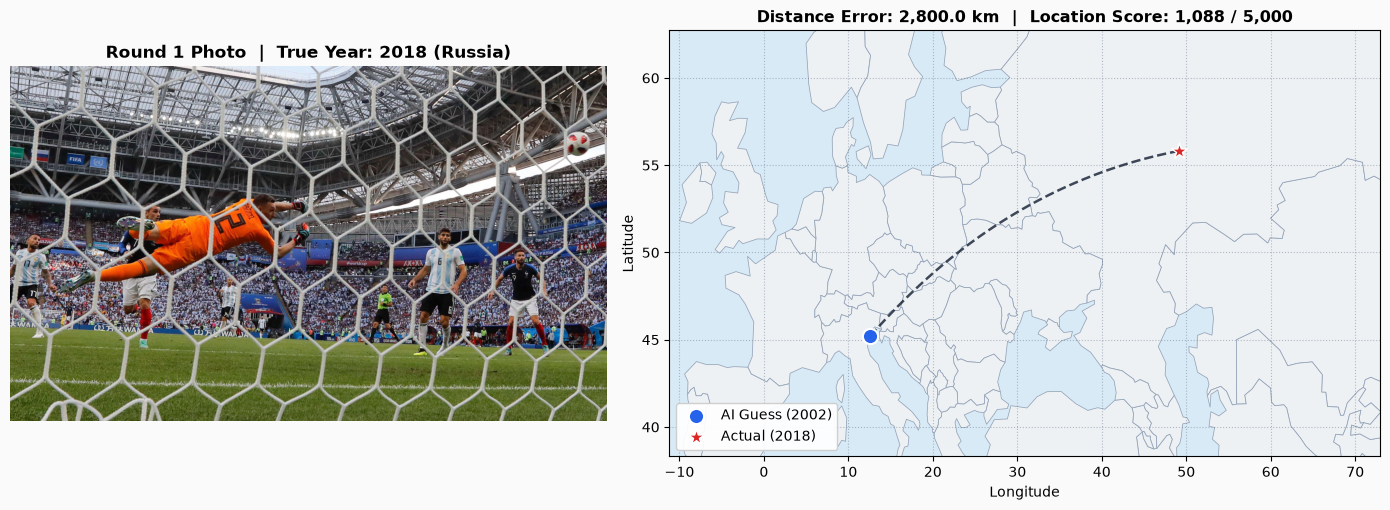

In [25]:
play_round(1)

### Round 2

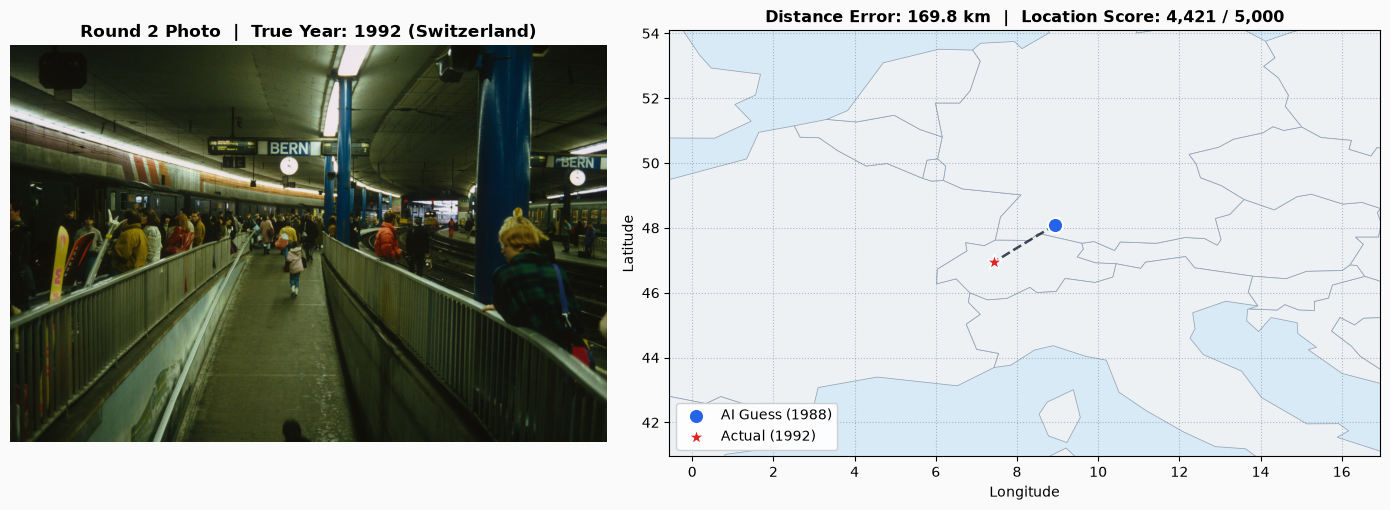

In [26]:
play_round(2)

### Round 3

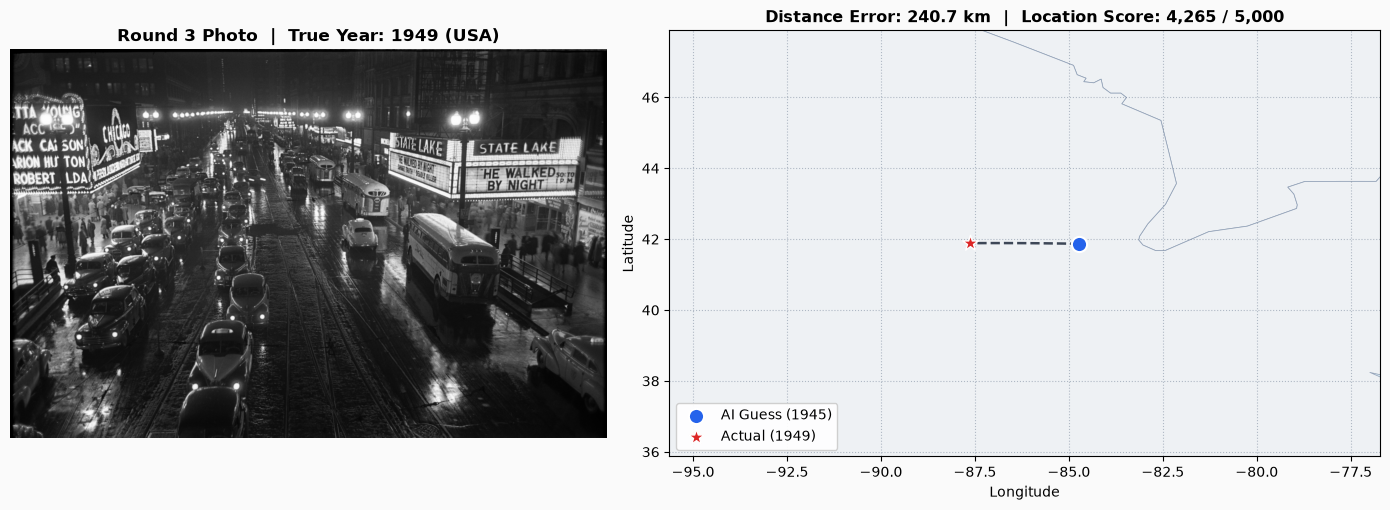

In [27]:
play_round(3)

### Round 4

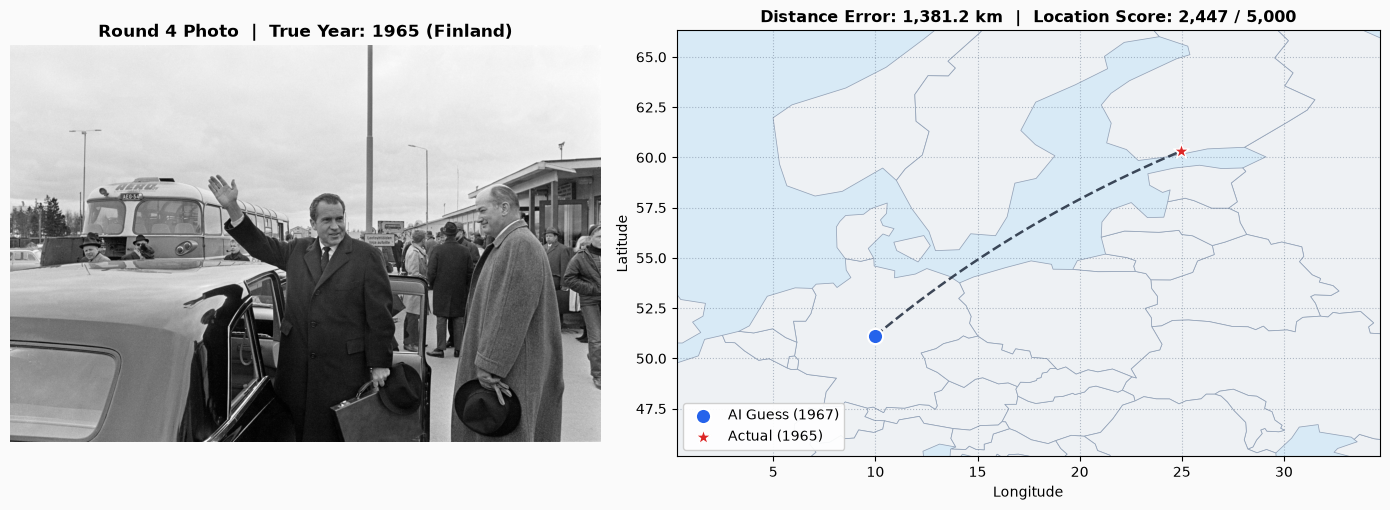

In [28]:
play_round(4)

### Round 5

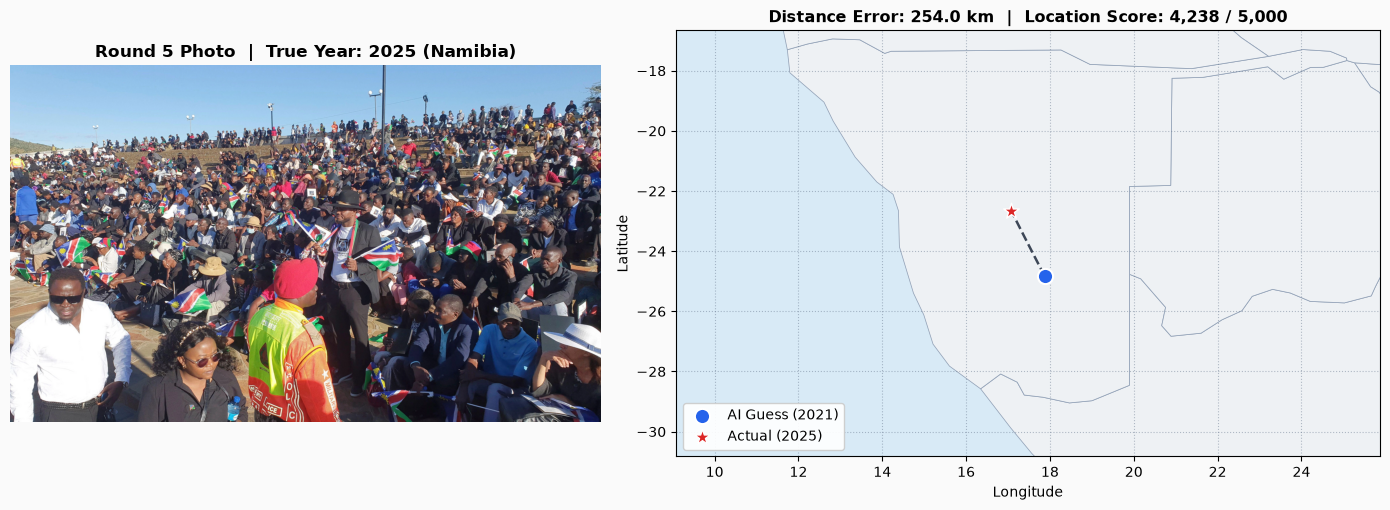

In [29]:
play_round(5)

## 4. Final Scoreboard & All-Player Distribution

Enter your final TimeGuessr score (out of `50,000`) in the input cell below, then run the next cell to compare **You vs. AI vs. All Players**.

In [30]:
# --- INPUT: Enter your final TimeGuessr score (0..50000) ---
YOUR_FINAL_SCORE = 35000

,Round,True Year,AI Year,Yrs Off,Year Pts,Country,Dist (km),Loc Pts,AI Total,Player Avg
0,1,2018,2002,16,1800,Russia,2799.96,1088,2888,7499.0
1,2,1992,1988,4,4500,Switzerland,169.79,4421,8921,8553.0
2,3,1949,1945,4,4500,USA,240.74,4265,8765,7887.0
3,4,1965,1967,2,4865,Finland,1381.18,2447,7312,7321.0
4,5,2025,2021,4,4500,Namibia,254.01,4238,8738,5916.0


  Linear Probe (StreetCLIP (ViT-L/14@336)) beat you by +1,624 points!
  Your Score : 35,000 / 50,000
  AI Score   : 36,624 / 50,000  (Year: 20,165 | Location: 16,459)
  Player Mean: 37,176 / 50,000
  Percentiles: You = 32.8th  |  AI = 43.5th


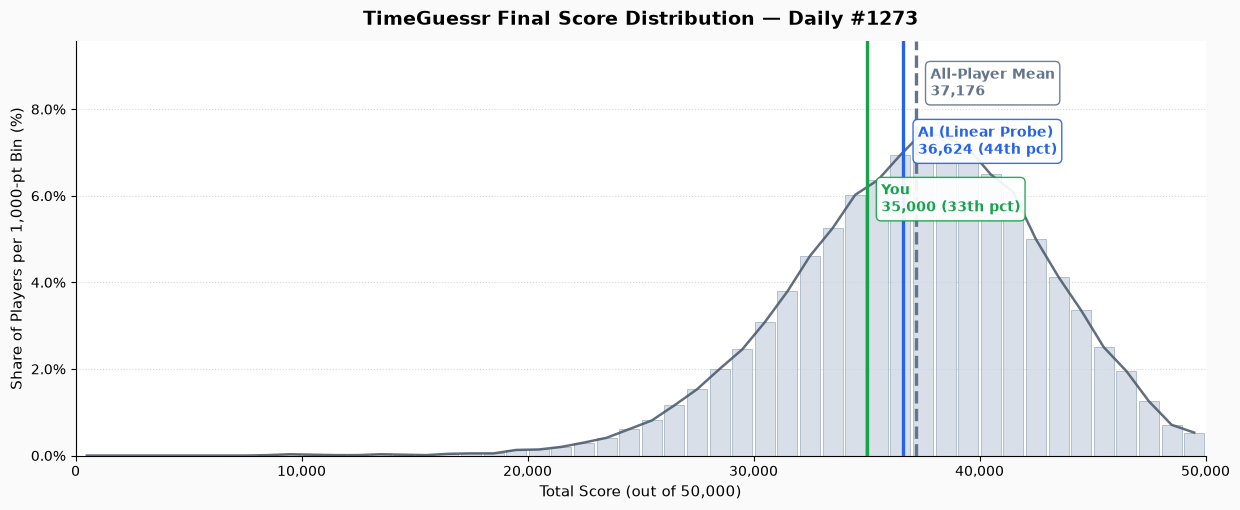

In [31]:
# Auto-run any unplayed rounds so the full 5-round total is always complete
for r_idx in range(1, len(game.rounds) + 1):
    if r_idx not in round_results:
        print(f"Running unplayed Round {r_idx} silently...")
        rd = game.get_round(r_idx)
        pred = predictor.predict(rd.image)
        sc = score_round(rd.true_lat, rd.true_lon, rd.true_year, pred.pred_lat, pred.pred_lon, pred.pred_year)
        r_stats = game.distribution.round_stats(r_idx) if game.distribution is not None else None
        round_results[r_idx] = {
            "round": r_idx,
            "true_year": rd.true_year,
            "pred_year": sc["pred_year_int"],
            "years_off": sc["years_off"],
            "true_country": rd.country,
            "pred_location": pred.location_label,
            "dist_km": sc["dist_km"],
            "year_score": sc["year_score"],
            "loc_score": sc["loc_score"],
            "total_score": sc["total_score"],
            "player_avg_score": r_stats.avg_score if r_stats else None,
        }

summary_df = pd.DataFrame([round_results[i] for i in sorted(round_results)])
ai_total = int(summary_df["total_score"].sum())
ai_year_total = int(summary_df["year_score"].sum())
ai_loc_total = int(summary_df["loc_score"].sum())

display_cols = [
    "round", "true_year", "pred_year", "years_off", "year_score",
    "true_country", "dist_km", "loc_score", "total_score", "player_avg_score",
]
display(summary_df[display_cols].rename(columns={
    "round": "Round",
    "true_year": "True Year",
    "pred_year": "AI Year",
    "years_off": "Yrs Off",
    "year_score": "Year Pts",
    "true_country": "Country",
    "dist_km": "Dist (km)",
    "loc_score": "Loc Pts",
    "total_score": "AI Total",
    "player_avg_score": "Player Avg",
}))

diff_you_ai = YOUR_FINAL_SCORE - ai_total
if diff_you_ai > 0:
    headline = f"You beat {predictor.name} by +{diff_you_ai:,} points!"
elif diff_you_ai < 0:
    headline = f"{predictor.name} beat you by +{-diff_you_ai:,} points!"
else:
    headline = f"Exact tie with {predictor.name}!"

print("=" * 68)
print(f"  {headline}")
print(f"  Your Score : {YOUR_FINAL_SCORE:6,d} / 50,000")
print(f"  AI Score   : {ai_total:6,d} / 50,000  (Year: {ai_year_total:,} | Location: {ai_loc_total:,})")
if game.distribution is not None:
    dist = game.distribution
    print(f"  Player Mean: {dist.avg_score:6,.0f} / 50,000")
    print(f"  Percentiles: You = {dist.percentile_of(YOUR_FINAL_SCORE):.1f}th  |  AI = {dist.percentile_of(ai_total):.1f}th")
print("=" * 68)

# --- TimeGuessr-Style Score Distribution Plot ---
if game.distribution is not None and len(game.distribution.histogram) > 0:
    dist = game.distribution
    centers = dist.bin_centers()
    probs = np.asarray(dist.histogram, dtype=np.float64)
    probs = probs / max(probs.sum(), 1e-12) * 100.0

    fig, ax = plt.subplots(figsize=(12.5, 5.2))
    fig.patch.set_facecolor("#fafafa")
    ax.set_facecolor("#ffffff")

    ax.bar(
        centers,
        probs,
        width=dist.bin_size * 0.88,
        color="#cbd5e1",
        edgecolor="#94a3b8",
        linewidth=0.6,
        alpha=0.75,
        label="All Players (1,000-pt bins)",
        zorder=2,
    )
    ax.plot(centers, probs, color="#475569", linewidth=1.8, alpha=0.85, zorder=3)

    ymax = float(probs.max()) * 1.28
    ax.set_ylim(0, ymax)
    ax.set_xlim(0, 50000)

    markers = [
        (dist.avg_score, f"All-Player Mean\n{dist.avg_score:,.0f}", "#64748b", "--", 0.94),
        (ai_total, f"AI ({predictor.name.split('(')[0].strip()})\n{ai_total:,} ({dist.percentile_of(ai_total):.0f}th pct)", "#2563eb", "-", 0.80),
        (YOUR_FINAL_SCORE, f"You\n{YOUR_FINAL_SCORE:,} ({dist.percentile_of(YOUR_FINAL_SCORE):.0f}th pct)", "#16a34a", "-", 0.66),
    ]

    for score_val, label_txt, color, ls, y_frac in markers:
        ax.axvline(score_val, color=color, linestyle=ls, linewidth=2.4, zorder=5)
        align = "left" if score_val < 38000 else "right"
        x_offset = 650 if align == "left" else -650
        ax.text(
            score_val + x_offset,
            ymax * y_frac,
            label_txt,
            color=color,
            fontsize=10,
            fontweight="bold",
            ha=align,
            va="top",
            bbox=dict(boxstyle="round,pad=0.35", facecolor="white", edgecolor=color, alpha=0.92),
            zorder=6,
        )

    title_suffix = f" — Daily #{game.daily_no}" if game.daily_no else f" — {game.mode.title()}"
    ax.set_title(f"TimeGuessr Final Score Distribution{title_suffix}", fontsize=14, fontweight="bold", pad=12)
    ax.set_xlabel("Total Score (out of 50,000)", fontsize=11)
    ax.set_ylabel("Share of Players per 1,000-pt Bin (%)", fontsize=11)
    ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(decimals=1))
    ax.grid(axis="y", linestyle=":", alpha=0.5)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()
    plt.show()
else:
    fig, ax = plt.subplots(figsize=(7, 4))
    names = ["You", predictor.name]
    vals = [YOUR_FINAL_SCORE, ai_total]
    colors = ["#16a34a", "#2563eb"]
    bars = ax.bar(names, vals, color=colors, width=0.5)
    ax.set_ylim(0, 50000)
    ax.set_ylabel("Total Score (out of 50,000)")
    ax.set_title("Final Score Comparison (No All-Player Distribution Available)")
    ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width() / 2, v + 800, f"{v:,}", ha="center", fontweight="bold")
    plt.tight_layout()
    plt.show()